<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Simulations climatiques</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 4: <br>Projection climatique et incertitudes</h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Projections and uncertainties (c.f. Cours 5)
    <br>
    Internal variability (c.f. Cours 2) 

</center>

## Introduction

Current climate change is primarily driven by the concentrations of greenhouse gases in the atmosphere, which are themselves a result of human activities. Hence, projections of future climate change for the next decades are based on different scenarios of greenhouse gases concentrations, reflecting different socio-economic pathways under several hypitheses (demographic, economic, politics, technologic, etc.). In the last IPCC assessment report [(IPCC AR6)](https://www.ipcc.ch/assessment-report/ar6/), these scenarios are called the _Shared Socioeconomic Pathways_ (SSP) and are classified in five distinct categories from SSP1 to SSP5 ([Fig. 1](#tp4-fig1)). Each category is declined in a suite of scenarios characterized by the end of century radiative forcing (e.g. 2.6, 4.5 and 8.5 W.m$^{-2}$ for SSP1-2.6, SSP2-4.5 and SSP5-8.5, respectively).

Climate models are then used to simulated climate evolution during the 21th century (and even further) for each scenario. Accuracy of these climate projections is function of three different factors ([Fig. 2](#tp4-fig2)):
1. **<span style="color: green;">scenario uncertainty</span>** driven by the choice in SSP scenarios, which alter the concentration of greenhouse gases and anthropic aerosols in the atmopshere resulting in different external focing. 
2. **<span style="color: blue;">model uncertainty</span>**, which quantifies modelling error in simulating the climate responses to external forcing, both from natural (solar radiation, volcanic aerosols, etc.) and anthropic sources.
3. **<span style="color: orange;">internal variability</span>** related to uding chaotic fluctuations of the climate dynamical system when subject to a constant or periodic external forcing (such as the annual cycle).


In this notebook, you will analyze climate projections from a suite of 20 CMIP6 climate models under three SSP (Shared Socio-Economic Pathway): SSP1-2.6, SSP2-4.5, SSP5-8.5. In particular, you will:
  - part 1: SSPs
  - part 2: Uncertainty on the global mean surface temperature
  - part 3: Other variables / regions
  - part 4: RCMs vs GCMs


<br>

<div align="center">
    <div id="tp4-fig1" style="width: 550px; float: left">
        <img src="../figures/IPCC-AR6-SPM-Fig3.png" alt="drawing" width="500"/>
    </div>
    <div id="tp4-fig2" style="width: 300px; float right">
        <br><br><br><br>
        <img src="../figures/Hawkins_and_Sutton-2009-Fig4.png" alt="drawing" width="400"/>
    </div>
    <br>
    <div>
    <div style="width: 550px; float: left">
    <b>Fig. 1. </b>Global surface temperature changes relative to 1850-1900 for five different shared socioeconomic pathways (SSPs). Taken from <a href="https://www.ipcc.ch/report/ar6/wg2/figures/summary-for-policymakers/">IPCC AR6 - SPM</a>.
    </div>
    <div style="width: 300px; float right">
    <b>Fig. 2. </b>The fraction of total variance in decadal mean surface air temperature predictions explained by the three components of total uncertainty for the global mean. Green regions represent scenario uncertainty, blue regions represent model uncertainty, and orange regions represent the internal variability component. Taken from <a href="https://doi.org/10.1175/2009BAMS2607.1">Hawkins and Sutton (2009)</a>.
    </div>
    </div>
</div>

<br><br><br><br>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [56]:
# manipulate file and data
import os
import numpy  as np
import pandas as pd
import xarray as xr
import scipy

# plotting
import matplotlib
import matplotlib.pyplot as plt

The code below loads results from 20 CMIP6 climate models for scenarios SSP1-2.6, SSP2-4.5 and SSP5-8.5.

In [4]:
# initialize empty dict to store variables
ssp126 = dict()
ssp245 = dict()
ssp585 = dict()


# load 20 models in csv (.asc) files using pandas and convert into xarray.Dataset
df = pd.read_csv('../data/'+"T_Glo_ANN_ssp126.asc", sep=" ")-273.15
ssp126['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_Glo_ANN_ssp245.asc", sep=" ")-273.15
ssp245['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_Glo_ANN_ssp585.asc", sep=" ")-273.15
ssp585['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# load some model outputs with precip in csv (.asc)
df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp126.asc", sep=" ", index_col=0)
ssp126['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp245.asc", sep=" ", index_col=0)
ssp245['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp585.asc", sep=" ", index_col=0)
ssp585['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# add CO2 emissions for each scenario
ar = np.loadtxt('../data/CO2/SSPs-CO2_emissions.csv', skiprows=1)
ssp126['co2_emissions'] = xr.DataArray(data=ar[:,1], dims=('year'), coords={'year': ar[:,0]})
ssp245['co2_emissions'] = xr.DataArray(data=ar[:,2], dims=('year'), coords={'year': ar[:,0]})
ssp585['co2_emissions'] = xr.DataArray(data=ar[:,3], dims=('year'), coords={'year': ar[:,0]})

print("Models loaded for 'ts': \n", list(ssp126['ts']['model'].data))
print("")
print("Models loaded for 'pr': \n", list(ssp126['pr']['model'].data))

Models loaded for 'ts': 
 ['ACCESS-CM2', 'MPI-ESM1-2-HR', 'UKESM1-0-LL', 'ACCESS-ESM1-5', 'CESM2-WACCM', 'INM-CM4-8', 'MPI-ESM1-2-LR', 'FGOALS-f3-L', 'INM-CM5-0', 'MRI-ESM2-0', 'CNRM-CM6-1-HR', 'IPSL-CM6A-LR', 'NorESM2-LM', 'CNRM-CM6-1', 'GISS-E2-1-G', 'MIROC6', 'NorESM2-MM', 'CNRM-ESM2-1', 'HadGEM3-GC31-LL', 'MIROC-ES2L']

Models loaded for 'pr': 
 ['ACCESS-CM2', 'EC-Earth3-Veg-LR', 'UKESM1-0-LL', 'CanESM5-CanOE', 'CMCC-ESM2', 'INM-CM4-8', 'MPI-ESM1-2-LR', 'FGOALS-f3-L', 'INM-CM5-0', 'MRI-ESM2-0', 'CNRM-CM6-1-HR', 'IPSL-CM6A-LR', 'NorESM2-LM', 'CNRM-CM6-1', 'GFDL-ESM4', 'MIROC6', 'NorESM2-MM', 'CNRM-ESM2-1', 'HadGEM3-GC31-LL', 'MIROC-ES2L']


Here, the global mean surface temperature (GMST) is available in three python dictionnaries `ssp126`, `ssp245` and `ssp585`.
You can access to the data, by using the variable name:

```python
    ssp126['ts']            # this return an xarray.DataArray object
    ssp126['ts'].data       # this return an numpy.array object
    ssp126['ts']['year']    # this return the 'year' coordinate for the variable 'ts'
```

In addition, we loaded CO$_2$ emissions combined from historical inventory and SSP scenarios:

```python
    ssp126['co2_emissions']  # this return an xarray.DataArray object
```

<a id="section-1"></a>
## 1. Shared Socioeconomics Pathways 

We first take a look into the trajectory of the three selected Shared Socioeconomic Pathways (SSPs): SSP1-2.6, SSP2-4.5 and SSP5-8.5. 

#### Question 1

* _Plot the time-series for CO$_2$ emissions in the three SSPs._
* _What do you see ?_


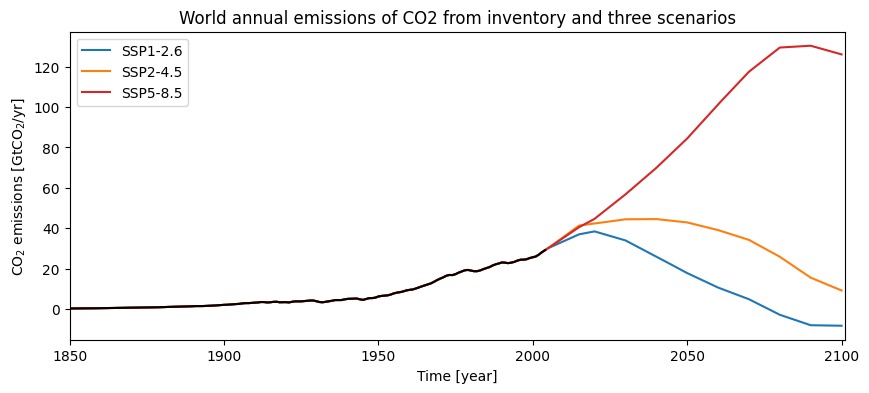

In [5]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( ssp126['co2_emissions']['year'], 1e-9*ssp126['co2_emissions'], label='SSP1-2.6', c='tab:blue')
ax.plot( ssp245['co2_emissions']['year'], 1e-9*ssp245['co2_emissions'], label='SSP2-4.5', c='tab:orange')
ax.plot( ssp585['co2_emissions']['year'], 1e-9*ssp585['co2_emissions'], label='SSP5-8.5', c='tab:red')
ax.plot( ssp126['co2_emissions']['year'][:155], 1e-9*ssp126['co2_emissions'][:155],       c='k')

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'CO$_2$ emissions [GtCO$_2$/yr]')

ax.set_xlim((1850, 2101))

ax.legend()

_ = ax.set_title("World annual emissions of CO2 from inventory and three scenarios")

<font color="blue">

- emissions have increased exponentially since 1950
- the 3 scenarios show different trajectory; it is worthnoting that SSP1-2.6 requires negative emissions to reach a low level of radiative forcing in 2100.
- Covid pandemic not seen here, seens the inventory ends in 2005
    
</font>

#### Question 2

* _Plot the time-series for global mean surface temperature (GMST) in the three SSPs._

__Help:__ remember that 20 models are used, all of them having a different pre-industrial global mean surface temperature level. It is therefore more convenient to work with anomalies of GMST $\Delta T_s$.

To avoid too much lines in your graph you can either split in several plots or use the functions [xarray.mean](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.mean.html) and [xarray.std](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.std.html) to characterize each scenario.

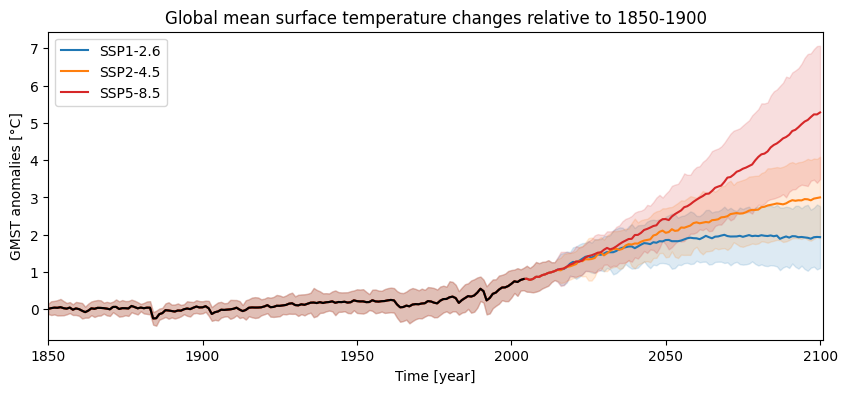

In [6]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# compute GMST anomalies
ssp126['tsa'] = (ssp126['ts'] - ssp126['ts'].isel({'year': slice(0, 50)}).mean('year'))
ssp245['tsa'] = (ssp245['ts'] - ssp245['ts'].isel({'year': slice(0, 50)}).mean('year'))
ssp585['tsa'] = (ssp585['ts'] - ssp585['ts'].isel({'year': slice(0, 50)}).mean('year'))

# get mean and std for each scenario
mean126 = ssp126['tsa'].mean('model')
std126  = ssp126['tsa'].std('model')

mean245 = ssp245['tsa'].mean('model')
std245  = ssp245['tsa'].std('model')

mean585 = ssp585['tsa'].mean('model')
std585  = ssp585['tsa'].std('model')

# plot multi-model mean
ax.plot( ssp126['ts']['year'], mean126,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], mean245,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], mean585,         label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].mean('model')[:155],   c='k')

# plot range
ax.fill_between( ssp126['ts']['year'], mean126+1.64*std126, mean126-1.64*std126, color='tab:blue',   alpha=0.15)
ax.fill_between( ssp245['ts']['year'], mean245+1.64*std245, mean245-1.64*std245, color='tab:orange', alpha=0.15)
ax.fill_between( ssp585['ts']['year'], mean585+1.64*std585, mean585-1.64*std585, color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature changes relative to 1850-1900")

<font color="blue">

- Discuss how the spread changes with time and with scenarios; why ?
    
- There is a correlation between warming and CO$_2$ emiisions
    
- $\Delta T_s$ in SSP2-4.5 still increases during all the 21th century even if CO$_2$ emissions decreases from year 2040.
    
- in the historical periods, there are some very rapid changes in temperature due to natural volcanic aerosols (external forcing) that tends to cool the climate
    
- scenario uncertainty is evident from 2050 to 2100; model uncertainty + internal variavility are shown with the 1.64$\sigma$ spread
    
</font>

#### Question 3 

* _Combine the two previous metrics by plotting temperature change against cummulative CO$_2$ emissions._
* _How do you intepret the figure ?_

__Help:__ you can compute cummulative emissions with the [xarray.cumsum](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.cumsum.html) function.

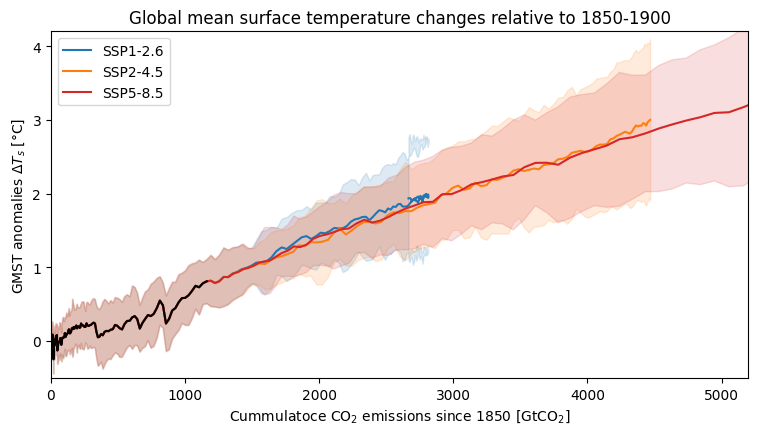

In [7]:
# plot
fig, ax = plt.subplots(1,1, figsize=(9, 4.5))

# get cummulative sum of CO2 emissions
cum_co2_ssp126 = 1e-9*ssp126['co2_emissions'].cumsum('year')
cum_co2_ssp245 = 1e-9*ssp245['co2_emissions'].cumsum('year')
cum_co2_ssp585 = 1e-9*ssp585['co2_emissions'].cumsum('year')

# plot multi-model mean against cummulative CO2
ax.plot( cum_co2_ssp126, mean126,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( cum_co2_ssp245, mean245,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( cum_co2_ssp585, mean585,         label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( cum_co2_ssp126[:155], ssp126['tsa'].mean('model')[:155],   c='k')

# plot range
ax.fill_between( cum_co2_ssp126, mean126+1.64*std126, mean126-1.64*std126, color='tab:blue',   alpha=0.15)
ax.fill_between( cum_co2_ssp245, mean245+1.64*std245, mean245-1.64*std245, color='tab:orange', alpha=0.15)
ax.fill_between( cum_co2_ssp585, mean585+1.64*std585, mean585-1.64*std585, color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Cummulatoce CO$_2$ emissions since 1850 [GtCO$_2$]')
ax.set_ylabel(r'GMST anomalies $\Delta T_s$ [°C]')

ax.set_xlim((0, 5200))
ax.set_ylim((-0.5, 4.2))

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature changes relative to 1850-1900")

<font color="blue">

- we retrieve the well known quasi linear relationship between $\Delta T_s$ and CO$_2$ emissions 
    
</font>

#### Question 4

* _Plot the time-series for global averaged precipitation in the three SSPs._
* _Can you find a correlation with another variable ? Why ?_

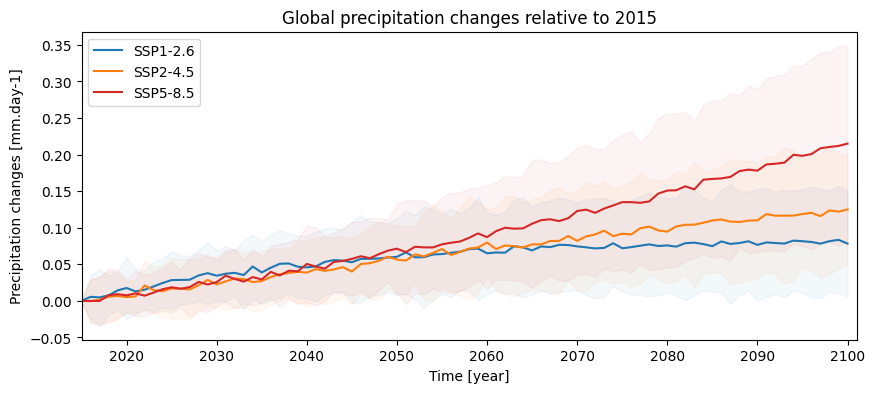

In [8]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# compute precipitation anomalies
ssp126['pra'] = (ssp126['pr'] - ssp126['pr'].isel({'year': 0}))
ssp245['pra'] = (ssp245['pr'] - ssp245['pr'].isel({'year': 0}))
ssp585['pra'] = (ssp585['pr'] - ssp585['pr'].isel({'year': 0}))

# get mean and std for each scenario
mean126_pr = ssp126['pra'].mean('model')
std126_pr  = ssp126['pra'].std('model')

mean245_pr = ssp245['pra'].mean('model')
std245_pr  = ssp245['pra'].std('model')

mean585_pr = ssp585['pra'].mean('model')
std585_pr  = ssp585['pra'].std('model')

# plot multi-model mean
ax.plot( ssp126['pr']['year'], mean126_pr,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['pr']['year'], mean245_pr,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['pr']['year'], mean585_pr,         label='SSP5-8.5', lw=1.5, c='tab:red')

# plot range
ax.fill_between( ssp126['pr']['year'], mean126_pr+1.64*std126_pr, mean126_pr-1.64*std126_pr, 
                                                                    color='tab:blue',   alpha=0.05)
ax.fill_between( ssp245['pr']['year'], mean245_pr+1.64*std245_pr, mean245_pr-1.64*std245_pr, 
                                                                    color='tab:orange', alpha=0.05)
ax.fill_between( ssp585['pr']['year'], mean585_pr+1.64*std585_pr, mean585_pr-1.64*std585_pr, 
                                                                    color='tab:red',    alpha=0.05)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'Precipitation changes [mm.day-1]')

ax.set_xlim((2015, 2101))

ax.legend(loc=2)

_ = ax.set_title("Global precipitation changes relative to 2015")

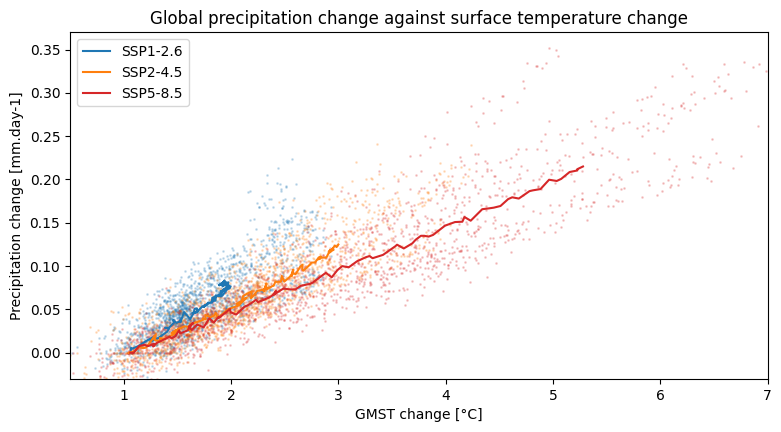

In [9]:
# plot
fig, ax = plt.subplots(1,1, figsize=(9, 4.5))

# compute precipitation anomalies
ssp126['pra'] = (ssp126['pr'] - ssp126['pr'].isel({'year': 0}))
ssp245['pra'] = (ssp245['pr'] - ssp245['pr'].isel({'year': 0}))
ssp585['pra'] = (ssp585['pr'] - ssp585['pr'].isel({'year': 0}))

# get mean and std for each scenario
mean126_pr = ssp126['pra'].mean('model')
std126_pr  = ssp126['pra'].std('model')

mean245_pr = ssp245['pra'].mean('model')
std245_pr  = ssp245['pra'].std('model')

mean585_pr = ssp585['pra'].mean('model')
std585_pr  = ssp585['pra'].std('model')

# plot multi-model mean
ax.plot( mean126.sel({'year': slice(2015,2101)}), mean126_pr, lw=1.5, label='SSP1-2.6', c='tab:blue')
ax.plot( mean245.sel({'year': slice(2015,2101)}), mean245_pr, lw=1.5, label='SSP2-4.5', c='tab:orange')
ax.plot( mean585.sel({'year': slice(2015,2101)}), mean585_pr, lw=1.5, label='SSP5-8.5', c='tab:red')

ax.scatter( ssp126['tsa'].sel({'year': slice(2015,2101)}), ssp126['pra'], s=1, alpha=0.2, c='tab:blue')
ax.scatter( ssp245['tsa'].sel({'year': slice(2015,2101)}), ssp245['pra'], s=1, alpha=0.2, c='tab:orange')
ax.scatter( ssp585['tsa'].sel({'year': slice(2015,2101)}), ssp585['pra'], s=1, alpha=0.2, c='tab:red')


# axe properties
ax.set_xlabel('GMST change [°C]')
ax.set_ylabel(r'Precipitation change [mm.day-1]')

ax.set_xlim((0.5, 7))
ax.set_ylim((-0.03, 0.37))

ax.legend(loc=2)

_ = ax.set_title("Global precipitation change against surface temperature change")

<font color="blue">

- **Modification of the global hydrological cycle.**

  - CLausius-Clapeyron: warmer atmosphere = water vapour in its constitution; in turn this leads to more evaporation/precipitation (intensification of the hydrological cycle)
    
  - the relation is linear with $\Delta T_s$ (and thus with cummulative CO$_2$)
    
</font>

<a id="section-2"></a>
## 2. Partitioning uncertainty

In this section, we will estimate the three uncertainty sources of climate projections, that come from <span style="color: green;">scenarios</span>, <span style="color: blue;">models</span> and <span style="color: orange;">internal variability</span>.

We will first try to extract the internal variability from the projection data sets. To do so, each prediction of the variable $X$ for a given model $m$, scenario $s$ and time $t$ is decomposed as a sum of several variability sources: 

$$ X(t, m, s) = x(t, m, s) + i(m, s) + \epsilon(t, m, s) $$

- $x$ is the response to external forcing (increase in the greenhouse gases concentration, variations of concentration in anthropogenic and natural aerosols, fluctuations in solar variability or volcanic eruptions and land‐use changes). In practice, it is evaluated as the smooth fit of $X$ on the total period in order to filter the internal variability component.
- $i$ is a reference value that depend to each model and scenario, which vanishes when dealing with anomalies. 
- the residual $\epsilon$ thus corresponds to the estimation of the internal variability.


The total uncertainty $T$ is then given by the sum of the three uncertainty sources:

$$ T(t) = \color{orange}{V} + \color{blue}{M(t)} + \color{green}{S(t)}$$
with :

- the uncertainty due to the internal variability $\color{orange}{V}$, considering as a constant, that means constant in time and independent of the scenario. We can thus define it from the variance of $\epsilon$ (and then by taking the multi-model mean of the variance):
$$\color{orange}{V = \frac{1}{N_{mod}} \sum_{m=1}^{N_{mod}} \textrm{Var}_{t,s}[\epsilon(m)]}$$
where $N_{mod}$ is the number of models.


- the model uncertainty $\color{blue}{M}$ that represents the different responses $x$ simulated by the different models. The multiscenario mean is taken as an estimate of the model uncertainty:
$$\color{blue}{M(t) = \frac{1}{N_{scen}} \sum_{s=1}^{N_{scen}} \textrm{Var}_{m}[x(t,s)]}$$
where $N_{scen}$ is the number of scenarios.


- the scenario uncertainty  $\color{blue}{S}$ is simply the variance of the multimodel means for the three scenarios:io mean is taken as an estimate of the model uncertainty:
$$\color{green}{S(t) = \textrm{Var}_{scen}\left[\frac{1}{N_{mod}} \sum_{m=1}^{N_{mod}} x(t,m)\right]}$$

#### Question 5

We will start by filtering the internal variability from the time-series of global mean surface temperature (GMST).

* _Choose one model and plot the time-series for global mean surface temperature (GMST) in the three SSPs._
* _Then, estimate the forced response of the selected model by smoothing time-series with a polynomial fit._

__Help:__ polynomial fit can be done in python with the [numpy Polynomial](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html#numpy.polynomial.polynomial.Polynomial.fit) class. Try several degrees and choose the one which works best.

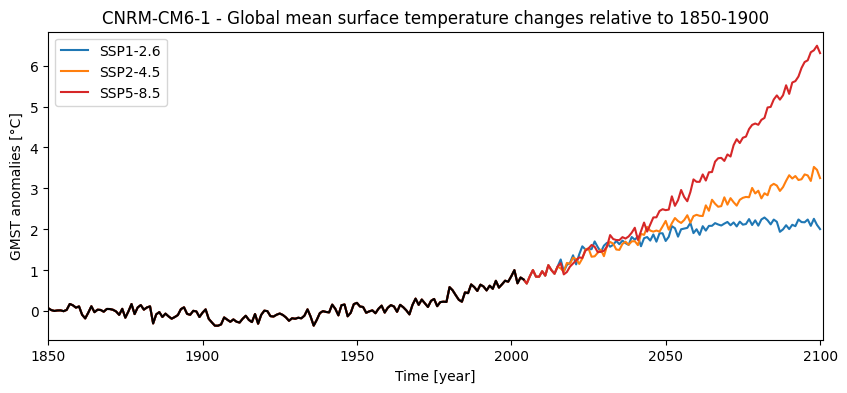

In [16]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# choose one model
model = 'CNRM-CM6-1'

# plot model time-series
ax.plot( ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].sel({'model': model})[:155],               c='k')

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("{} - Global mean surface temperature changes relative to 1850-1900".format(model))

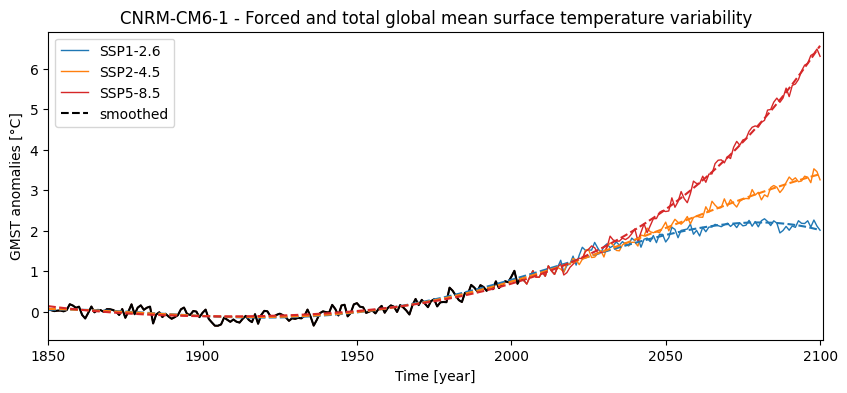

In [54]:
# Compute polynomial fit
deg          = 4

coefs_ssp126 = np.polyfit(ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), deg)
coefs_ssp245 = np.polyfit(ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), deg)
coefs_ssp585 = np.polyfit(ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), deg)

frcd_ssp126  = np.polyval(coefs_ssp126, ssp126['ts']['year'])
frcd_ssp245  = np.polyval(coefs_ssp245, ssp245['ts']['year'])
frcd_ssp585  = np.polyval(coefs_ssp585, ssp585['ts']['year'])

# create figure and axe 
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# plot model time-series
ax.plot( ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), label='SSP1-2.6', lw=1., c='tab:blue')
ax.plot( ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), label='SSP2-4.5', lw=1., c='tab:orange')
ax.plot( ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), label='SSP5-8.5', lw=1., c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].sel({'model': model})[:155],              c='k')

# plot model smoothed time-series
ax.plot( ssp126['ts']['year'], frcd_ssp126, lw=1.5, ls='--', c='tab:blue')
ax.plot( ssp245['ts']['year'], frcd_ssp245, lw=1.5, ls='--', c='tab:orange')
ax.plot( ssp585['ts']['year'], frcd_ssp585, lw=1.5, ls='--', c='tab:red')
ax.plot( [0, 1], [1, 1], label='smoothed',  lw=1.5, ls='--', c='k')

# ax properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("{} - Forced and total global mean surface temperature variability".format(model))

<font color="blue">

- a fourth order polynomial fit provides the best results, and it is the choice done in [Hawkins and Sutton (2009)](https://doi.org/10.1007/s00382-010-0810-6).
        
</font>

#### Question 6

* _Using the `welch` function ([scipy.signal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html)) plot the power spectral density for global mean surface temperature time-series as well as the forced and internal variability._
* _How do you interpret the results ? Is your filtering method seems correct ? If you would be able to run a climate model, propose a method to better estimate the internal variability._ 


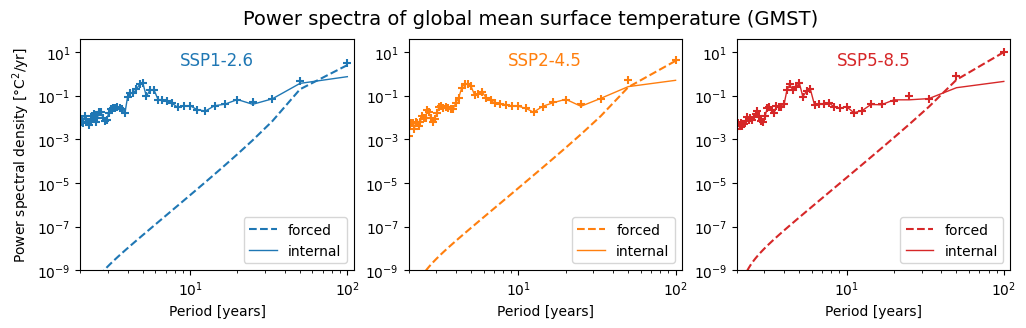

In [226]:
fig, axes = plt.subplots(1,3, figsize=(12, 3))


# power spectra for the full signal (anomalies of GMST) 
f126, p126 = scipy.signal.welch(ssp126['tsa'].sel({'model': model}), fs=1, scaling='density', nperseg=100)
f245, p245 = scipy.signal.welch(ssp245['tsa'].sel({'model': model}), fs=1, scaling='density', nperseg=100)
f585, p585 = scipy.signal.welch(ssp585['tsa'].sel({'model': model}), fs=1, scaling='density', nperseg=100)

axes[0].scatter(1/f126[1:],   p126[1:], s=30, marker='+', c='tab:blue' )
axes[1].scatter(1/f245[1:],   p245[1:], s=30, marker='+', c='tab:orange' )
axes[2].scatter(1/f585[1:],   p585[1:], s=30, marker='+', c='tab:red' )


# power spectra for the forced variability only
f126, p126 = scipy.signal.welch(frcd_ssp126, fs=1, scaling='density', nperseg=100)
f245, p245 = scipy.signal.welch(frcd_ssp245, fs=1, scaling='density', nperseg=100)
f585, p585 = scipy.signal.welch(frcd_ssp585, fs=1, scaling='density', nperseg=100)

axes[0].plot(1/f126[1:],   p126[1:], label='forced', ls='--', lw=1.5, c='tab:blue' )
axes[1].plot(1/f245[1:],   p245[1:], label='forced', ls='--', lw=1.5, c='tab:orange' )
axes[2].plot(1/f585[1:],   p585[1:], label='forced', ls='--', lw=1.5, c='tab:red' )


# power spectra for the internal variability only
f126, p126 = scipy.signal.welch(ssp126['tsa'].sel({'model': model}) - frcd_ssp126, fs=1, scaling='density', 
                                nperseg=100)
f245, p245 = scipy.signal.welch(ssp245['tsa'].sel({'model': model}) - frcd_ssp245, fs=1, scaling='density', 
                                nperseg=100)
f585, p585 = scipy.signal.welch(ssp585['tsa'].sel({'model': model}) - frcd_ssp585, fs=1, scaling='density', 
                                nperseg=100)

axes[0].plot(1/f126[1:],   p126[1:], label='internal', ls='-', lw=1., c='tab:blue' )
axes[1].plot(1/f245[1:],   p245[1:], label='internal', ls='-', lw=1., c='tab:orange' )
axes[2].plot(1/f585[1:],   p585[1:], label='internal', ls='-', lw=1., c='tab:red' )


# ax parameters
axes[0].set_title('SSP1-2.6', y=0.85, c='tab:blue' )
axes[1].set_title('SSP2-4.5', y=0.85, c='tab:orange' )
axes[2].set_title('SSP5-8.5', y=0.85, c='tab:red' )

for i, ax in enumerate(axes):
    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlim((2, 110))
    ax.set_xlabel(r'Period [years]')
    
    ax.set_ylim((1e-9, 40))
    if i == 0:
        ax.set_ylabel(r'Power spectral density [°C$^2$/yr]')

    ax.legend(loc=4)

_ = fig.suptitle('Power spectra of global mean surface temperature (GMST)', fontsize=14)

<font color="blue">

power spectra allow to compare signals by decomposing into a sum of finite simple signals (using Fourier transform). The energy or the density of each signal is estimated and plotted against its frequency. 
    
The figure highlights how our method has filtered the GMST anomaly time-series. The polynomial fit (i.e. the forced signal in dashed line) clearly keep the shortest frequencies (>30 years) while higher frequencies are absent (not the log scale). In contrast, the residuals (i.e. the internal variability in solid line) conserve the signal at high frequencies but reduce the spectral density for longer periods. To a first order, the method can extract the internal variability from the original time-series. 
    
Few remarks :
  - we can aleready note that the internal variability is similar between scenario; this supports the definition of a constant internal variability $V$
  - internal variability at low frequencies does not vanished due to some decadal / centenial variability (different from one model to another)
  - the forced signal is stronger for higher radiative forcing scenario (SSP5 vs. SSP1)

</font>

#### Question 7

* _Compute the forced and internal variability for each model._
* _Propose figures that check the differences between models. How can you explain the differences ?_

In [208]:
# init empty arrays
forced_ssp126 = np.zeros_like(ssp126['tsa'])
forced_ssp245 = np.zeros_like(ssp245['tsa'])
forced_ssp585 = np.zeros_like(ssp585['tsa'])

internal_ssp126 = forced_ssp126.copy()
internal_ssp245 = forced_ssp126.copy()
internal_ssp585 = forced_ssp126.copy()

# Compute fourth-order polynomial fit
deg           = 4
    
for im, model in enumerate(ssp126['ts']['model']):
    coefs_ssp126 = np.polyfit(ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), deg)
    coefs_ssp245 = np.polyfit(ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), deg)
    coefs_ssp585 = np.polyfit(ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), deg)

    forced_ssp126[:,im]  = np.polyval(coefs_ssp126, ssp126['ts']['year'])
    forced_ssp245[:,im]  = np.polyval(coefs_ssp245, ssp245['ts']['year'])
    forced_ssp585[:,im]  = np.polyval(coefs_ssp585, ssp585['ts']['year'])
    
# compute internal variability
internal_ssp126 = ssp126['tsa'] - forced_ssp126
internal_ssp245 = ssp245['tsa'] - forced_ssp245
internal_ssp585 = ssp585['tsa'] - forced_ssp585

# save in python dictionaries
ssp126['tsa_forced'] = xr.DataArray(data=forced_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_forced'] = xr.DataArray(data=forced_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_forced'] = xr.DataArray(data=forced_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)

ssp126['tsa_internal'] = xr.DataArray(data=internal_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_internal'] = xr.DataArray(data=internal_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_internal'] = xr.DataArray(data=internal_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)

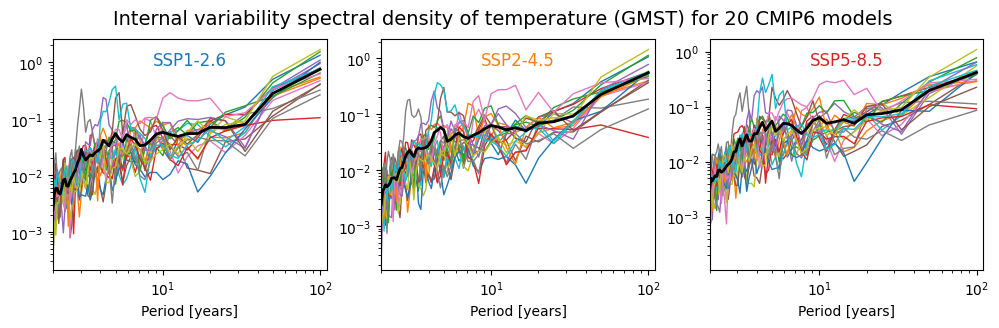

In [246]:
# plot
fig, axes = plt.subplots(1,3, figsize=(12, 3))

# SSP1 power spectra
f, pw = scipy.signal.welch(ssp126['tsa_internal'], fs=1, axis=0, scaling='density', 
                           nperseg=100)
axes[0].plot(1/f[1:],   pw[1:],              lw=1.)
axes[0].plot(1/f[1:],   pw[1:].mean(axis=1), lw=2., c='k')


# SSP2 power spectra
f, pw = scipy.signal.welch(ssp245['tsa_internal'], fs=1, axis=0, scaling='density', 
                           nperseg=100)
axes[1].plot(1/f[1:],   pw[1:],              lw=1.)
axes[1].plot(1/f[1:],   pw[1:].mean(axis=1), lw=2., c='k')


# SSP1 power spectra
f, pw = scipy.signal.welch(ssp585['tsa_internal'], fs=1, axis=0, scaling='density', 
                           nperseg=100)
axes[2].plot(1/f[1:],   pw[1:],              lw=1.)
axes[2].plot(1/f[1:],   pw[1:].mean(axis=1), lw=2., c='k')


# axes properties
axes[0].set_title('SSP1-2.6', y=0.85, c='tab:blue' )
axes[1].set_title('SSP2-4.5', y=0.85, c='tab:orange' )
axes[2].set_title('SSP5-8.5', y=0.85, c='tab:red' )

for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlim((2, 110))
    ax.set_xlabel(r'Period [years]')
    
    if i == 0:
        ax.set_ylabel(r'Power spectral density [°C$^2$/yr]')
    
_ = fig.suptitle("Internal variability spectral density of temperature (GMST) for 20 CMIP6 models", fontsize=14)

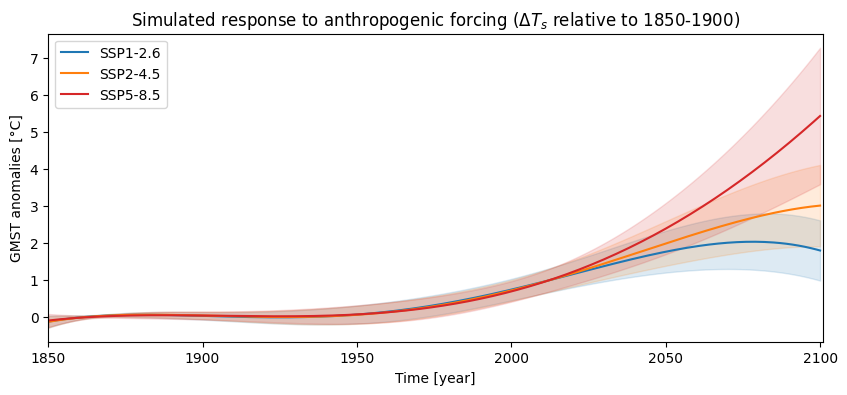

In [218]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# get mean and std for each scenario
mean126_frcd = ssp126['tsa_forced'].mean('model')
std126_frcd  = ssp126['tsa_forced'].std('model')

mean245_frcd = ssp245['tsa_forced'].mean('model')
std245_frcd  = ssp245['tsa_forced'].std('model')

mean585_frcd = ssp585['tsa_forced'].mean('model')
std585_frcd  = ssp585['tsa_forced'].std('model')

# plot multi-model mean
ax.plot( ssp126['ts']['year'], mean126_frcd,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], mean245_frcd,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], mean585_frcd,         label='SSP5-8.5', lw=1.5, c='tab:red')

# plot range
years = ssp126['ts']['year']
ax.fill_between( years, mean126_frcd+1.64*std126_frcd, mean126_frcd-1.64*std126_frcd, 
                                                                color='tab:blue',   alpha=0.15)
ax.fill_between( years, mean245_frcd+1.64*std245_frcd, mean245_frcd-1.64*std245_frcd, 
                                                                color='tab:orange', alpha=0.15)
ax.fill_between( years, mean585_frcd+1.64*std585_frcd, mean585_frcd-1.64*std585_frcd, 
                                                                color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title(r"Simulated response to anthropogenic forcing ($\Delta T_s$ relative to 1850-1900)")

<font color="blue">
   
Discuss here differences in 1) internal variability and 2) forced response.
    
For 1) we can note differences in power signal at all frequencies; even the centenial variability is very different across models
    
For 2) even if all models are based on physical equations (transport and conservation equations), they use different numerical choices (how to solve the equation) and different modelling choices (how to represent processes). In particular, climate models cannot fully resolve small-scale processes, such as those related to clouds – which are thought to be important for climate sensitivity.
    
  - **Are these differences are problematic ?**\
    Not necessary. We can remark that they give similar trends (global surface temperature increase, as well as upward longwave radiation). This is rather reassuring in the sense that we can trust their results in broad terms. CMIP results feed the IPCC Assessment Reports in which confidence levels on climate metrics are given from that model results match or not.
    

  - **Which model is the best ?**\
    Probably none. Models are often run on historical period (1950-today) and compared to observations. However, the answer will be different depending on the metric considered to evaluate the model. Indeed, no model performs well everywhere. Regarding future climate projection, it is often admit that the multi model mean gives the best estimate while the standard deviation gives the uncertainty.


</font>

#### Question 8

* _Use the definition of the three uncertainty sources to compute $V$, $M$ and $S$ for the global mean surface temperature._
* _Normalize each source with the total uncertainty to create a figure similar to the one in introduction ([Fig. 2](#tp4-fig2)). Interpret and comment your results._

In [287]:
# Compute uncertainty sources

# 1. Internal variability (V)
internal_var = xr.concat( (ssp126['tsa_internal'], ssp245['tsa_internal'], ssp585['tsa_internal']), dim='year')

iv_variance = internal_var.var(axis=0)    # variance across the scenarios and the years
iv_mea      = iv_variance.mean().data     # multi-model mean
V           = np.ones_like(years)*iv_mea

# 2. Model uncertainty (M)
M_ssp126 = ssp126['tsa_forced'].var(axis=1)
M_ssp245 = ssp245['tsa_forced'].var(axis=1)
M_ssp585 = ssp585['tsa_forced'].var(axis=1)

M = 1/3 * (M_ssp126 + M_ssp245 + M_ssp585).data # multi-scenario mean

# 3. Scenario uncertainty
forced_avg =  xr.concat( (mean126_frcd, mean245_frcd, mean585_frcd), dim='scenario')

S = forced_avg.var(dim='scenario').data    # variance across the scenarios

# Total uncertainty
total_unc = V + M + S

/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


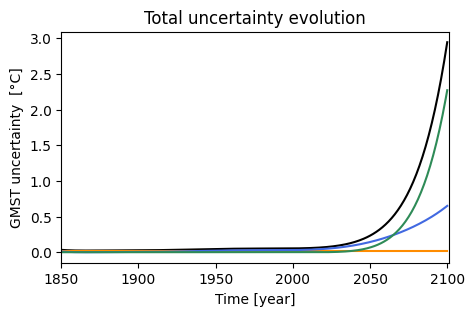

In [290]:
# First, check that total uncertainty T increases with time
fig, ax = plt.subplots(1,1, figsize=(5, 3))

# plot multi-model mean
ax.plot( years, total_unc,  c='k')
ax.plot( years, V,          c='darkorange')
ax.plot( years, M,          c='royalblue')
ax.plot( years, S,          c='seagreen')

ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST uncertainty  [°C]')

ax.set_xlim((1850, 2101))

_ = ax.set_title(r"Total uncertainty evolution")

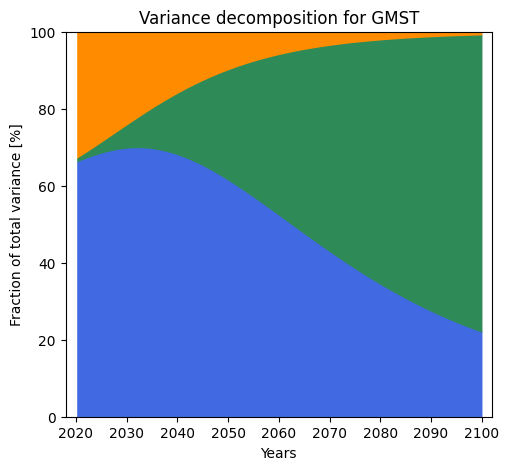

In [312]:
# Plot uncertainty decomposition
fig, ax = plt.subplots(1,1, figsize=(5.5, 5))

# plot fraction
ax.fill_between( years, 100*M/total_unc, np.zeros_like(M),                  color='royalblue')
ax.fill_between( years, 100*(M + S)/total_unc,      100*M/total_unc,        color='seagreen')
ax.fill_between( years, 100*(M + S + V)/total_unc , 100*(M + S)/total_unc,  color='darkorange')

#
ax.set_ylim((0,100))
ax.set_xlim((2018, 2102))
ax.fill_between( [2018, 2020], [100, 100], [0, 0],  color='white')
ax.set_ylabel('Fraction of total variance [%]')
ax.set_xlabel('Years')

_ = ax.set_title(r"Variance decomposition for GMST")

<font color="blue">

- **At short/mid term** (< 2040) the scenario makes little difference and most of the uncertainty is due to the models.:

  -  _modelling choices_ (parameters) cause difference between models
 
  -  the simulated climate still have an _internal variability_. Indeed, climate variables exhibit natural fluctuations meaning that two simulations starting from a different state (but with the same climate in a statistical sense) will give different results. This leads to uncertainties that climate scientists try to quantify. In practive, several simulations of the same individual model are runs with different initialisation (intial state). *Tens* of simulations of *tens* model for *different* scenario $\rightarrow$ this is really really costly and a non-negligeable source of greenhouse gases emissions..

- **At long term** (>2050) the choosen scenario matters a lot !! 

</font>

<a id="section-3"></a>
## 3. Application to other variables and finer regions


In the previous sections, we have analyzed the Earth energy balance and showed how the climate respond to an external CO$_2$ forcing. We will now try to understand the mechanisms that drive this response.

Climate feedbacks are internal mechanisms which can alter the response to an initial perturbation. We call a _positive_ and _negative_ feedback when the mechanism tends to amply or diminish the response, respectively.

#### Question 9

* _Recall relatively known radiative feedbacks and try to relate them to the terms involved in the Earth energy balance ([section 1](#section-1))_    

<font color="blue">

From the lectures (Cours 3) of J. Cattiaux, there are few main feedbacks that arise from a CO$_2$ forcing:
    
  - __Water vapour feedback__ that arise because a warmer air has a greater capacity to contain vapour before being saturated. Since the water vapour is a greenhouse gas, the feedback is __positive__. This mechanism is not directly related to a energy flux term but itstead increase the external forcing term $F$ in the energy balance.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow F_{GHG}^\nearrow \rightarrow T_s^\nearrow $$
    
    
  - __The lapse rate feedback__ is due because the troposphere does not warm similarly in all the air column, resulting in a change of the emission temperature $T_e$ and thus, a change in the longwave upward energy flux ($\sigma T_e^4$). THis could be __positive or negative__ (in fact this depend on the geography).
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \Delta \partial_z T \rightarrow \Delta T_e \rightarrow \Delta T_s $$

    
  - __Albedo feedback__ that arise in a change of the albedo parameter $\alpha$ (i.e. the capacity of the system to reflect solar radiation) through the term $\alpha S_0/4$. This can reflect either a change in the surface albedo or a change in clouds reflection. Surface albedo is overall __positive__ but sign of the cloud feedbacks in still uncertain.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \alpha^\searrow \rightarrow SW_\mathrm{up}^\searrow \rightarrow T_s^\nearrow $$
    
    
   - __Clouds__ can also alter the atmosphere transmissivity $\tau_a$, hence changing the longwave emission term \sigma T_e^4. However, large uncertainty arise from clouds in climate models so that sign of the feedback remains unknown.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \Delta \tau_a \rightarrow \Delta \sigma T_e \rightarrow \Delta T_s $$
</font>

#### Question 10

We will now focus on the effect of the clouds in the _abrupt-4xCO2_ experiment.

* _Using the clear-sky variables (e.g. rlutcs) propose a figure illustrating clouds effect._    

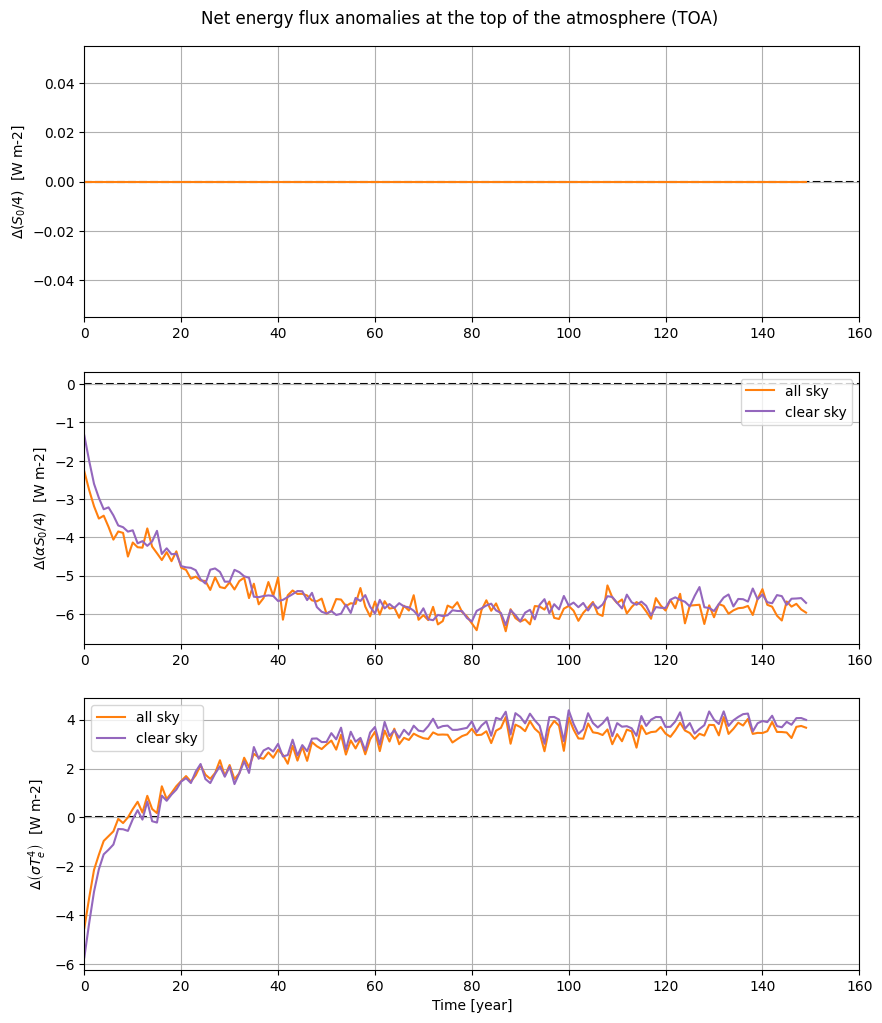

In [13]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))

dRLUT     = (abrupt['rlut'] - piCtrl['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt['rsut'] - piCtrl['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt['rsdt'] - piCtrl['rsdt']).groupby('time.year').mean()

dRLUTCS   = (abrupt['rlutcs'] - piCtrl['rlutcs']).groupby('time.year').mean()
dRSUTCS   = (abrupt['rsutcs'] - piCtrl['rsutcs']).groupby('time.year').mean()

# dR
axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:orange')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:orange', label='all sky')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:orange', label='all sky')

axes[1].plot( np.arange(len(dRSUTCS['year'])), dRSUTCS, c='tab:purple', label='clear sky')
axes[2].plot( np.arange(len(dRLUTCS['year'])), dRLUTCS, c='tab:purple', label='clear sky')

axes[0].set_ylabel(r'$\Delta \left(S_0/4\right)$  [W m-2]')
axes[1].set_ylabel(r'$\Delta \left(\alpha S_0/4\right)$  [W m-2]')
axes[2].set_ylabel(r'$\Delta \left(\sigma T_e^4\right)$  [W m-2]')

for ax in axes:
    ax.hlines(0,0,160, color="k", ls="--", alpha=1, zorder=-10)
    ax.grid(True)
    ax.set_xlim((0, 160))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')
    
    if ax != axes[0]:
        ax.legend()


_ = fig.suptitle("Net energy flux anomalies at the top of the atmosphere (TOA)", y=0.91)

<font color="blue">

CNRM-CM6-1 simulates weak differences of energy flux anomalies (between _piControl_ and _abrupt-4xCO2_) indicating that the cloud feedback is weak. However, it is important to note that clouds feedback is really sensitive to model configuration (resolution, cloud scheme, etc.) and a different conclusion could arise with another model. It is therefore important to use multi-model analysis.
    
Interestingly, the difference between all sky and clear sky variables are marked in both _piControl_ and _abrupt-4xCO2_ (not shown) but the response is similar. This shows that the change in radiative fluxes arise from another mechanisms, at least in CNRM-CM6-1. 

</font>

#### Question 11

We will now focus on the surface albedo feedback.

* _Using surface variables, propose one or several figures illustrating the albedo feedback._    

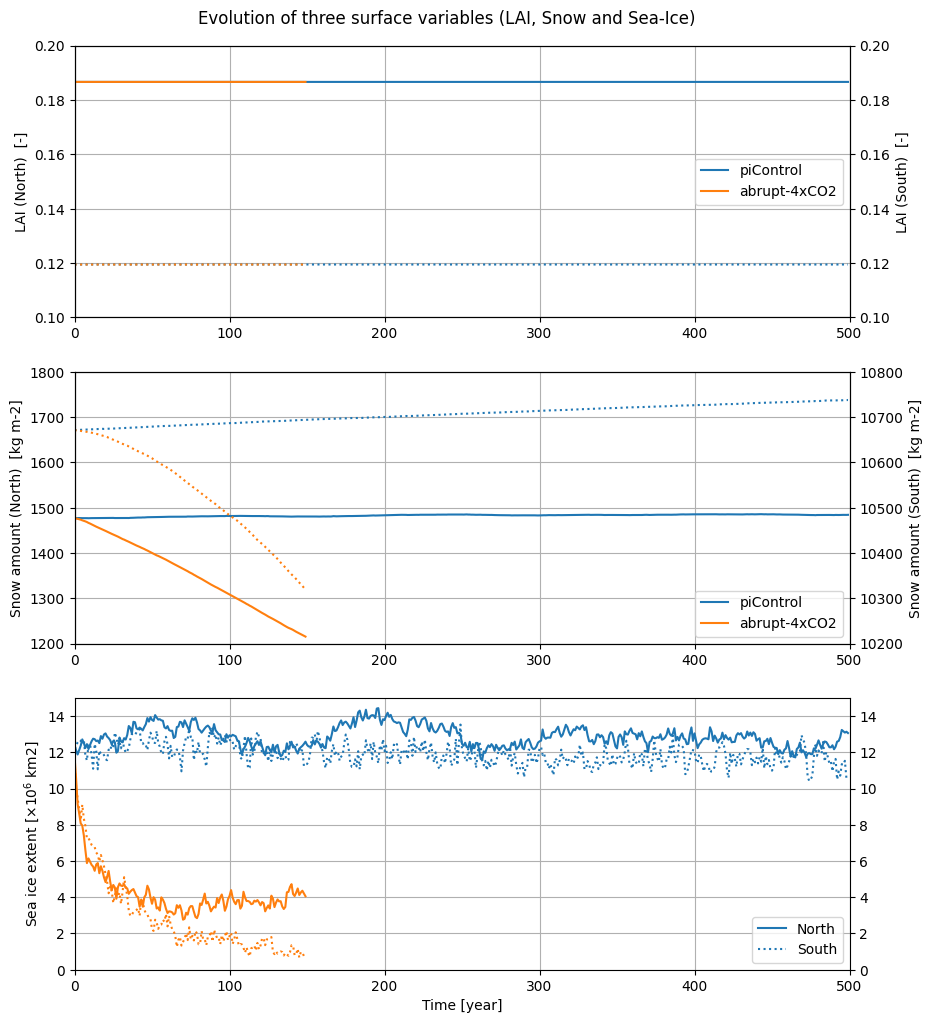

In [14]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))


# piCtrl variables
lain     = (piCtrl['lain']).groupby('time.year').mean()
lais     = (piCtrl['lais']).groupby('time.year').mean()

snwn     = (piCtrl['snwn']).groupby('time.year').mean()
snws     = (piCtrl['snws']).groupby('time.year').mean()

siextn   = (piCtrl['siextentn']).groupby('time.year').mean()
siexts   = (piCtrl['siextents']).groupby('time.year').mean()

# abrupt variables
lain_a   = (abrupt['lain']).groupby('time.year').mean()
lais_a   = (abrupt['lais']).groupby('time.year').mean()

snwn_a   = (abrupt['snwn']).groupby('time.year').mean()
snws_a   = (abrupt['snws']).groupby('time.year').mean()

siextn_a = (abrupt['siextentn']).groupby('time.year').mean()
siexts_a = (abrupt['siextents']).groupby('time.year').mean()


# LAI
axes[0].plot( lain['year']-1850  , lain,   c='tab:blue',   ls='-' , label='piControl')
axes[0].plot( lain_a['year']-1850, lain_a, c='tab:orange', ls='-' , label='abrupt-4xCO2')
axes[0].legend(loc=5)

twinx_0 = axes[0].twinx()
twinx_0.plot( lais['year']-1850,   lais,   c='tab:blue',   ls=':')
twinx_0.plot( lais_a['year']-1850, lais_a, c='tab:orange', ls=':')

axes[0].set_ylim((0.1, 0.2))
twinx_0.set_ylim((0.1, 0.2))

axes[0].set_ylabel(r'LAI (North)  [-]')
twinx_0.set_ylabel(r'LAI (South)  [-]')


# Snow
axes[1].plot( snwn['year']-1850,   snwn,   c='tab:blue',   ls='-',  label='piControl')
axes[1].plot( snwn_a['year']-1850, snwn_a, c='tab:orange', ls='-' , label='abrupt-4xCO2')
axes[1].legend(loc=4)

twinx_1 = axes[1].twinx()
twinx_1.plot( snws['year']-1850,   snws,   c='tab:blue',   ls=':')
twinx_1.plot( snws_a['year']-1850, snws_a, c='tab:orange', ls=':')

axes[1].set_ylim((1200,  1800))
twinx_1.set_ylim((10200, 10800))

axes[1].set_ylabel(r'Snow amount (North)  [kg m-2]')
twinx_1.set_ylabel(r'Snow amount (South)  [kg m-2]')


# Sea ice
axes[2].plot( siextn['year']-1850, siextn, c='tab:blue', ls='-',  label='North')
axes[2].plot( siexts['year']-1850, siexts, c='tab:blue', ls=':', label='South')

axes[2].plot( siextn_a['year']-1850, siextn_a, c='tab:orange', ls='-')
axes[2].plot( siexts_a['year']-1850, siexts_a, c='tab:orange', ls=':')

axes[2].set_ylim((0, 15))
axes[2].set_ylabel(r'Sea ice extent [$\times 10^6$ km2]')

axes[2].yaxis.set_ticks_position('both')
axes[2].tick_params(labelright=True)
axes[2].legend()


for ax in axes:   
    ax.grid(True)    
    ax.set_xlim((0, 500))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')
        

_ = fig.suptitle("Evolution of three surface variables (LAI, Snow and Sea-Ice) ", y=0.91)

<font color="blue">

Here we have plotted three different metrics showing surface changes during the two experiments. 
Each metric is decomposed into a northern and southern hemisphere value.

  - __Leaf area index__ (LAI) is a variable that represent the surface of vegetation per unit of area at the ground. Note that since vegetation occupies a 3D space, the LAI ratio can be greater than 1 (0 is a desert or urban area while 6 is highly dense forest such as tropical forests). In our simulations, the LAI metrics is constant and is not altered by the increase in CO$_2$ concentration (at least at the global scale). It is worth noting that the model used here does not represent the carbon cycle and the forest expansion is perhaps limited.   
    
    
  - As expected, most of the differences are found for the cryosphere (__snow amount__ and __sea_ice__). In particular, the sea ice exhibits a large retreat in both hemisphere in the forcing experiment. It is interesting to note that the sea-ice timeseries seems well correlated to the evolution of the upward shortwave radiation showing that it likely drives this change. One can note that, sea-ice extents are approximately similar in both hemisphere, but the northern ice shelf stabilize at a value twice than that of the southern. Conversely, snow amount is ten times greater in the southern hemispere (mostly due to the presence of the Antarctic) but exhibits the largest loss (around 350 kg.m-2). In the north, the loss is linear and reaches 280 kg.m-2 at the end of the _abrupt-4xcO2_ simulation.

Here we have highlighted the well known surface albedo feedback, which is mainly driven by changes in the cryosphere. However, it should be noted that the impact of the cryosphere in a changing climate is not limited to the albedo but includes air-sea interaction, ocean circulation alteration, water-cycle, etc..
    

</font>

#### Question 12

* _Using the figures and results you have plotted, propose a method to quantify the relative effect of a feedback._ 

__Help:__ we can assume a pre-industrial surface albedo $\alpha_0 \sim 0.3$

In [15]:
# Here, we focus on the surface albedo feedback

# First, compute the change in alpha
alpha_0     = 0.3
solar_in    = float(piCtrl['rsdt'].mean())           # or 1368/4 
piCtrl_SWup = float(piCtrl['rsut'].mean())
abrupt_SWup = float(abrupt['rsut'][-12*50:].mean())

alpha_f  = alpha_0 + (abrupt_SWup-piCtrl_SWup) / solar_in

# Then, compute the effective sensitivity parameter lambda
coeff_a  = - solar_in * (alpha_f-alpha_0) / ecs

print(r"New global surface albedo = {:.2f}".format(alpha_f))
print(r"Effective surface albedo sensitivity parameter = {:.2f} [W.m-2.K-1]".format(coeff_a))

New global surface albedo = 0.28
Effective surface albedo sensitivity parameter = 0.56 [W.m-2.K-1]


<font color="blue">

In the previous sections, we have shown :
  - the radiative budget is affected by the forcing in a similar way for all-sky and clear-sky conditions, illustrating a weak impact of clouds
  - the incoming solar radiation is constant though the simulation for each experiment
    
As a consequence, all surface changes that alter the upward radiative flux can be consider in a change in the global $\alpha$ parameter, so that:
    $$\Delta(\alpha S_0/4) = (\alpha_f - \alpha_0) S_0/4 = \Delta \mathrm{LW}_\text{up}$$

This give the new climate albedo $\alpha_f$ under CO$_2$ forcing:
    $$\alpha_f = \alpha_0 + \Delta \mathrm{LW}_\text{up} \times 4/S_0 \approx 0.28$$
    
To quantify the contribution of the albedo feedback to the climate sensitivity, one can compute the effective response relative to albedo:
    $$ \lambda_\alpha = \frac{\partial R}{\partial \alpha}\frac{\partial \alpha}{\partial T_s} = - S_0/4 \frac{\partial \alpha}{\partial T_s}$$
    
Or by linearized the previous equaition: $\lambda_\alpha = -S_0/4 \frac{\Delta \alpha}{\Delta T_s} \approx 0.56 \;\mathrm{W m}^{-2} \mathrm{K}^{-1}$
    
This value is larger but in the range of the expected value (0.35 $\pm$ 0.25 W.m-2.K-1) but calculation here have been made with short forcing simulation, and errors could arise from the choice in the global equilibrated variable (such as the ECS).
</font>

#### Going further (optional)

In the previous sections, we have relate the Earth energy balance with physical and climate variables. 
However, there are still topics to explore if wanted. Among other:

* _For now, we have mainly explained the variation in the shortwave upward flux. What are the mechanisms that drive the upward longwave changes ?._
* _We have seen that the increase in surface temperature can drive a surface albedo feedback. Howeve, we have only made calculation using global integrated value. Finer analysing is often required to spatialize and understand where the changes occur._
* _There are plenty of variables that are simulated by general circulation models, you can ask fo any ideas or wishes that is able to satisfy your curiosity !_

## 4. Conclusion and discussion

TODO: mettre plusieurs modèles CMIP pour calculer l'incertitude sur ECS + lambda !

We conclude the notebook by using output from another CMIP6 model. The following lines, will load global overaged monthly outputs from the ACCESS-CM2 climate model [(Bi et al., 2020)](https://connectsci.au/es/article/70/1/225/73456/Configuration-and-spin-up-of-ACCESS-CM2-the-new)) developped by the Australian climate modelling community:   


```python
# initialize empty dict to store variables
piCtrl_cm2 = dict()
abrupt_cm2 = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]
    
    # select only ACCESS-CM2 model
    if model == 'ACCESS-CM2':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)
        
        if expe == 'piControl':
            piCtrl_cm2[var]      = ds[list(ds.variables)[-1]]
            piCtrl_cm2[var].name = var
        elif expe == 'abrupt-4xCO2':
            abrupt_cm2[var]      = ds[list(ds.variables)[-1]]
            abrupt_cm2[var].name = var
            
print("Variables loaded in piCtrl_cm2: \n", list(piCtrl_cm2.keys()))
print("")
print("Variables loaded in abrupt_cm2: \n", list(abrupt_cm2.keys())) 
```

#### Question 13

* _Compare some of the results you have obtained from CNRM-CM6-1 by computing similar metrics with the new experiments._
* _Comment on the similarities and differences. What about uncertainty of your results ?_ 

In [43]:
# initialize empty dict to store variables
piCtrl_cm2 = dict()
abrupt_cm2 = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]

    # select only ACCESS-CM2 model
    if model == 'ACCESS-CM2':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)

        if expe == 'piControl':
            piCtrl_cm2[var]      = ds[list(ds.variables)[-1]]
            piCtrl_cm2[var].name = var
        elif expe == 'abrupt-4xCO2':
            abrupt_cm2[var]      = ds[list(ds.variables)[-1]]
            abrupt_cm2[var].name = var

print("Variables loaded in piCtrl_cm2: \n", list(piCtrl_cm2.keys()))
print("")
print("Variables loaded in abrupt_cm2: \n", list(abrupt_cm2.keys())) 

Variables loaded in piCtrl_cm2: 
 ['rsdt', 'ts', 'rsutcs', 'rsut', 'rlut', 'rlutcs']

Variables loaded in abrupt_cm2: 
 ['rlutcs', 'rsdt', 'rsut', 'rsutcs', 'ts', 'rlut']


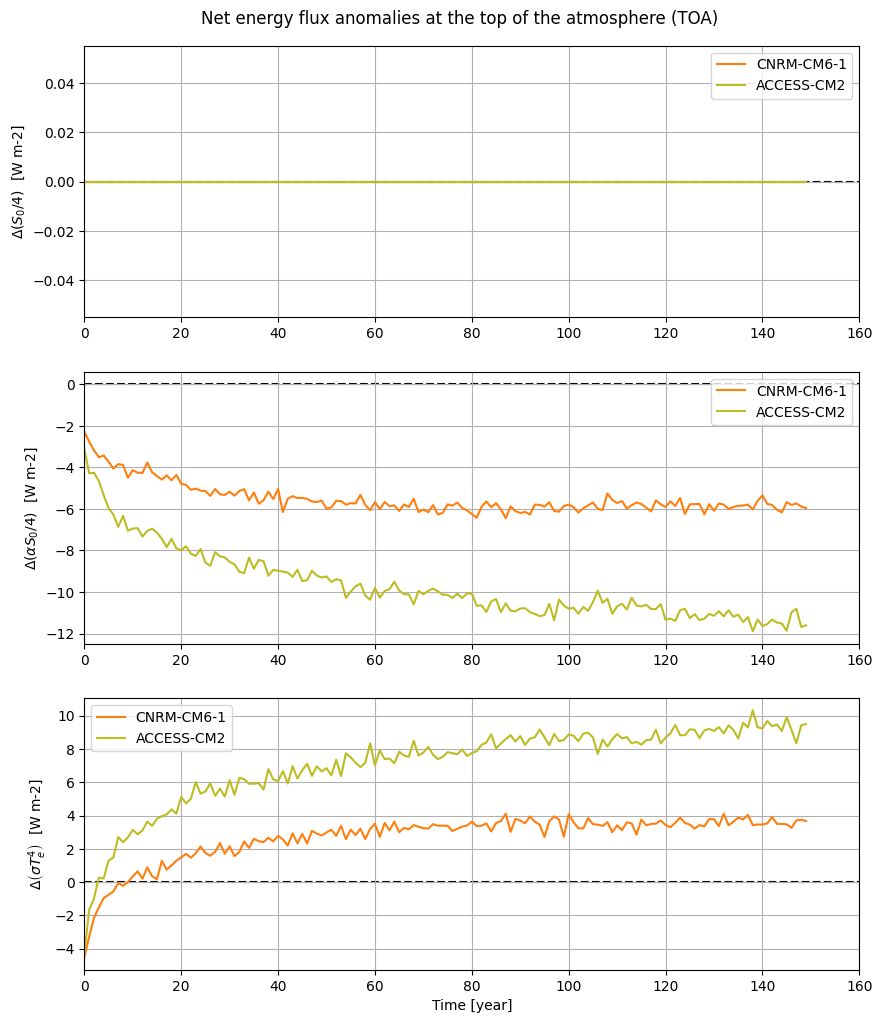

In [46]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))


# dR (CNRM_CM6-1)
dRLUT     = (abrupt['rlut'] - piCtrl['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt['rsut'] - piCtrl['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt['rsdt'] - piCtrl['rsdt']).groupby('time.year').mean()

axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:orange', label='CNRM-CM6-1')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:orange', label='CNRM-CM6-1')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:orange', label='CNRM-CM6-1')


# dR (ACCESS-CM2)
dRLUT     = (abrupt_cm2['rlut'] - piCtrl_cm2['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt_cm2['rsut'] - piCtrl_cm2['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt_cm2['rsdt'] - piCtrl_cm2['rsdt']).groupby('time.year').mean()

axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:olive', label='ACCESS-CM2')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:olive', label='ACCESS-CM2')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:olive', label='ACCESS-CM2')


# Axes
axes[0].set_ylabel(r'$\Delta \left(S_0/4\right)$  [W m-2]')
axes[1].set_ylabel(r'$\Delta \left(\alpha S_0/4\right)$  [W m-2]')
axes[2].set_ylabel(r'$\Delta \left(\sigma T_e^4\right)$  [W m-2]')

for ax in axes:
    ax.hlines(0,0,160, color="k", ls="--", alpha=1, zorder=-10)
    ax.legend()
    ax.grid(True)
    ax.set_xlim((0, 160))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')

_ = fig.suptitle("Net energy flux anomalies at the top of the atmosphere (TOA)", y=0.91)

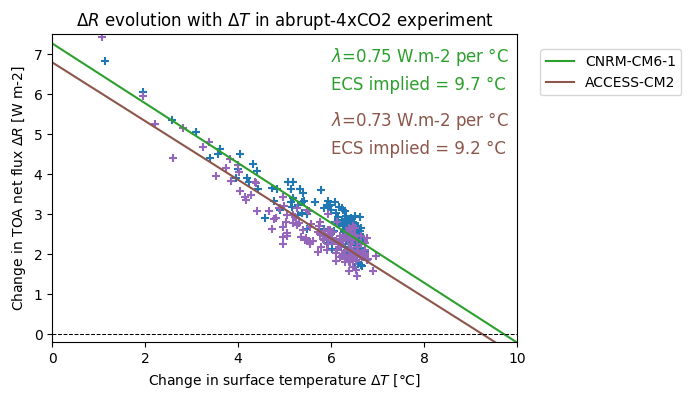

In [56]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))


# CNRM-CM6-1: compute and plot linear trend + ECS
ax.scatter( dT, dR, marker='+', c='tab:blue')

x         = np.vstack([dT, np.ones(len(dT))]).T
coeff, R0 = np.linalg.lstsq(x, dR, rcond=-1)[0]

ecs       = -R0 / coeff  # dT = -dR/lambda

# -- plot trend
ax.plot( np.linspace(0, 10, 100), coeff * np.linspace(0, 10, 100) + R0, ls='-', c='tab:green', label='CNRM-CM6-1')
ax.text(6, 6.8,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:green')
ax.text(6, 6.1, r"ECS implied = {:.1f} °C".format(ecs),           fontsize=12,  c='tab:green')


# ACCESS-CM2: compute and plot linear trend + ECS
dR_piCtrl_cm2 = (piCtrl_cm2['rsdt'] - piCtrl_cm2['rsut'] - piCtrl_cm2['rlut']).groupby('time.year').mean()
dR_abrupt_cm2 = (abrupt_cm2['rsdt'] - abrupt_cm2['rsut'] - abrupt_cm2['rlut']).groupby('time.year').mean()

dT_access    = (abrupt_cm2['ts'] - piCtrl_cm2['ts']).groupby('time.year').mean()
dR_access    =  dR_abrupt_cm2    - dR_piCtrl_cm2

# -- plot scatter points
ax.scatter( dT_access, dR_access, marker='+', c='tab:purple')

x            = np.vstack([dT_access, np.ones(len(dT_access))]).T
coef_cm2, R0 = np.linalg.lstsq(x, dR_access, rcond=-1)[0]

ecs_cm2      = -R0 / coef_cm2  # dT = -dR/lambda

# -- plot trend
ax.plot( np.linspace(0, 10, 100), coefa * np.linspace(0, 10, 100) + R0, ls='-', c='tab:brown', label='ACCESS-CM2')
ax.text(6, 5.2,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coef_cm2), fontsize=12,  c='tab:brown')
ax.text(6, 4.5, r"ECS implied = {:.1f} °C".format(ecs_cm2),     fontsize=12,  c='tab:brown')

# plot y=0 line
ax.plot( [0, 10], [0, 0], ls='--', lw=0.75, c='k')


# axe properties
ax.set_xlim((0, 10))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

ax.legend(loc=(1.05,0.8))

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

<font color="blue">

Here, we can let the student do their own analysis..
    
</font>

#### Question 14

* _Propose a summary and conclusion of the notebook._ 

<font color="blue">

Conclusion should include:
    
  - short presentation of the lecture (simulations used here, for what purposes, etc.)
  - method and main results
  - discussion (uncertainty, limitations, how to reduce these limitations, etc.)
  - conclusion (e.g. what have they learned during the lecture)

</font>